In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!nvidia-smi

Wed Oct 28 12:56:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
!pip install -q ultralytics==8.4.189 roboflow

In [7]:
import ultralytics, PIL
print('ultralytics', ultralytics.__version__, '| pillow', PIL.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.189 | pillow 13.0.0


In [8]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

key = UserSecretsClient().get_secret('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=key)
project = rf.workspace('processing-workspace').project('football-l9zew')
dataset = project.version(6).download('yolov8', location='/kaggle/working/football')
DATA = f'{dataset.location}/data.yaml'
RUNS = '/kaggle/working/fv_runs'
print(DATA)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/football in yolov8:: 100%|██████████| 1511/1511 [00:00<00:00, 9812.63it/s]

/kaggle/working/football/data.yaml


In [9]:
import glob
for s in ['train', 'valid', 'test']:
    print(s, len(glob.glob(f'/kaggle/working/football/{s}/images/*')))   # expect 568, 96, 89

from ultralytics import YOLO
YOLO('yolo26n.pt').train(data=DATA, epochs=1, imgsz=640, batch=16, device=0,
                         project='/kaggle/working/smoke', name='s', exist_ok=True)

train 568
valid 96
test 89
New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/football/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=tr

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


Optimizer stripped from /kaggle/working/smoke/s/weights/best.pt, 5.4MB

Validating /kaggle/working/smoke/s/weights/best.pt...
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.2s2.3s4s
                   all         96       2135   0.000465    0.00647    1.5e-05   2.53e-06
                  ball         82         82          0          0          0          0
            goalkeeper         95         95          0          0          0          0
                player         96       1585    0.00186     0.0259   6.01e-05   1.01e-05
               referee         96        373          0          0          0          0
Speed: 2.0ms preprocess, 34.7ms inference, 0.0ms loss, 10.0ms postprocess per image
Results saved to /kaggle/working/smoke/s


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e6dc404df90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [10]:
model = YOLO('yolo26n.pt')
model.train(data=DATA, epochs=60, imgsz=960, batch=16, patience=15,
            cache=True, device=0, project=RUNS, name='n_960')

New https://pypi.org/project/ultralytics/8.4.191 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/football/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, mom

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e6e6bf30050>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

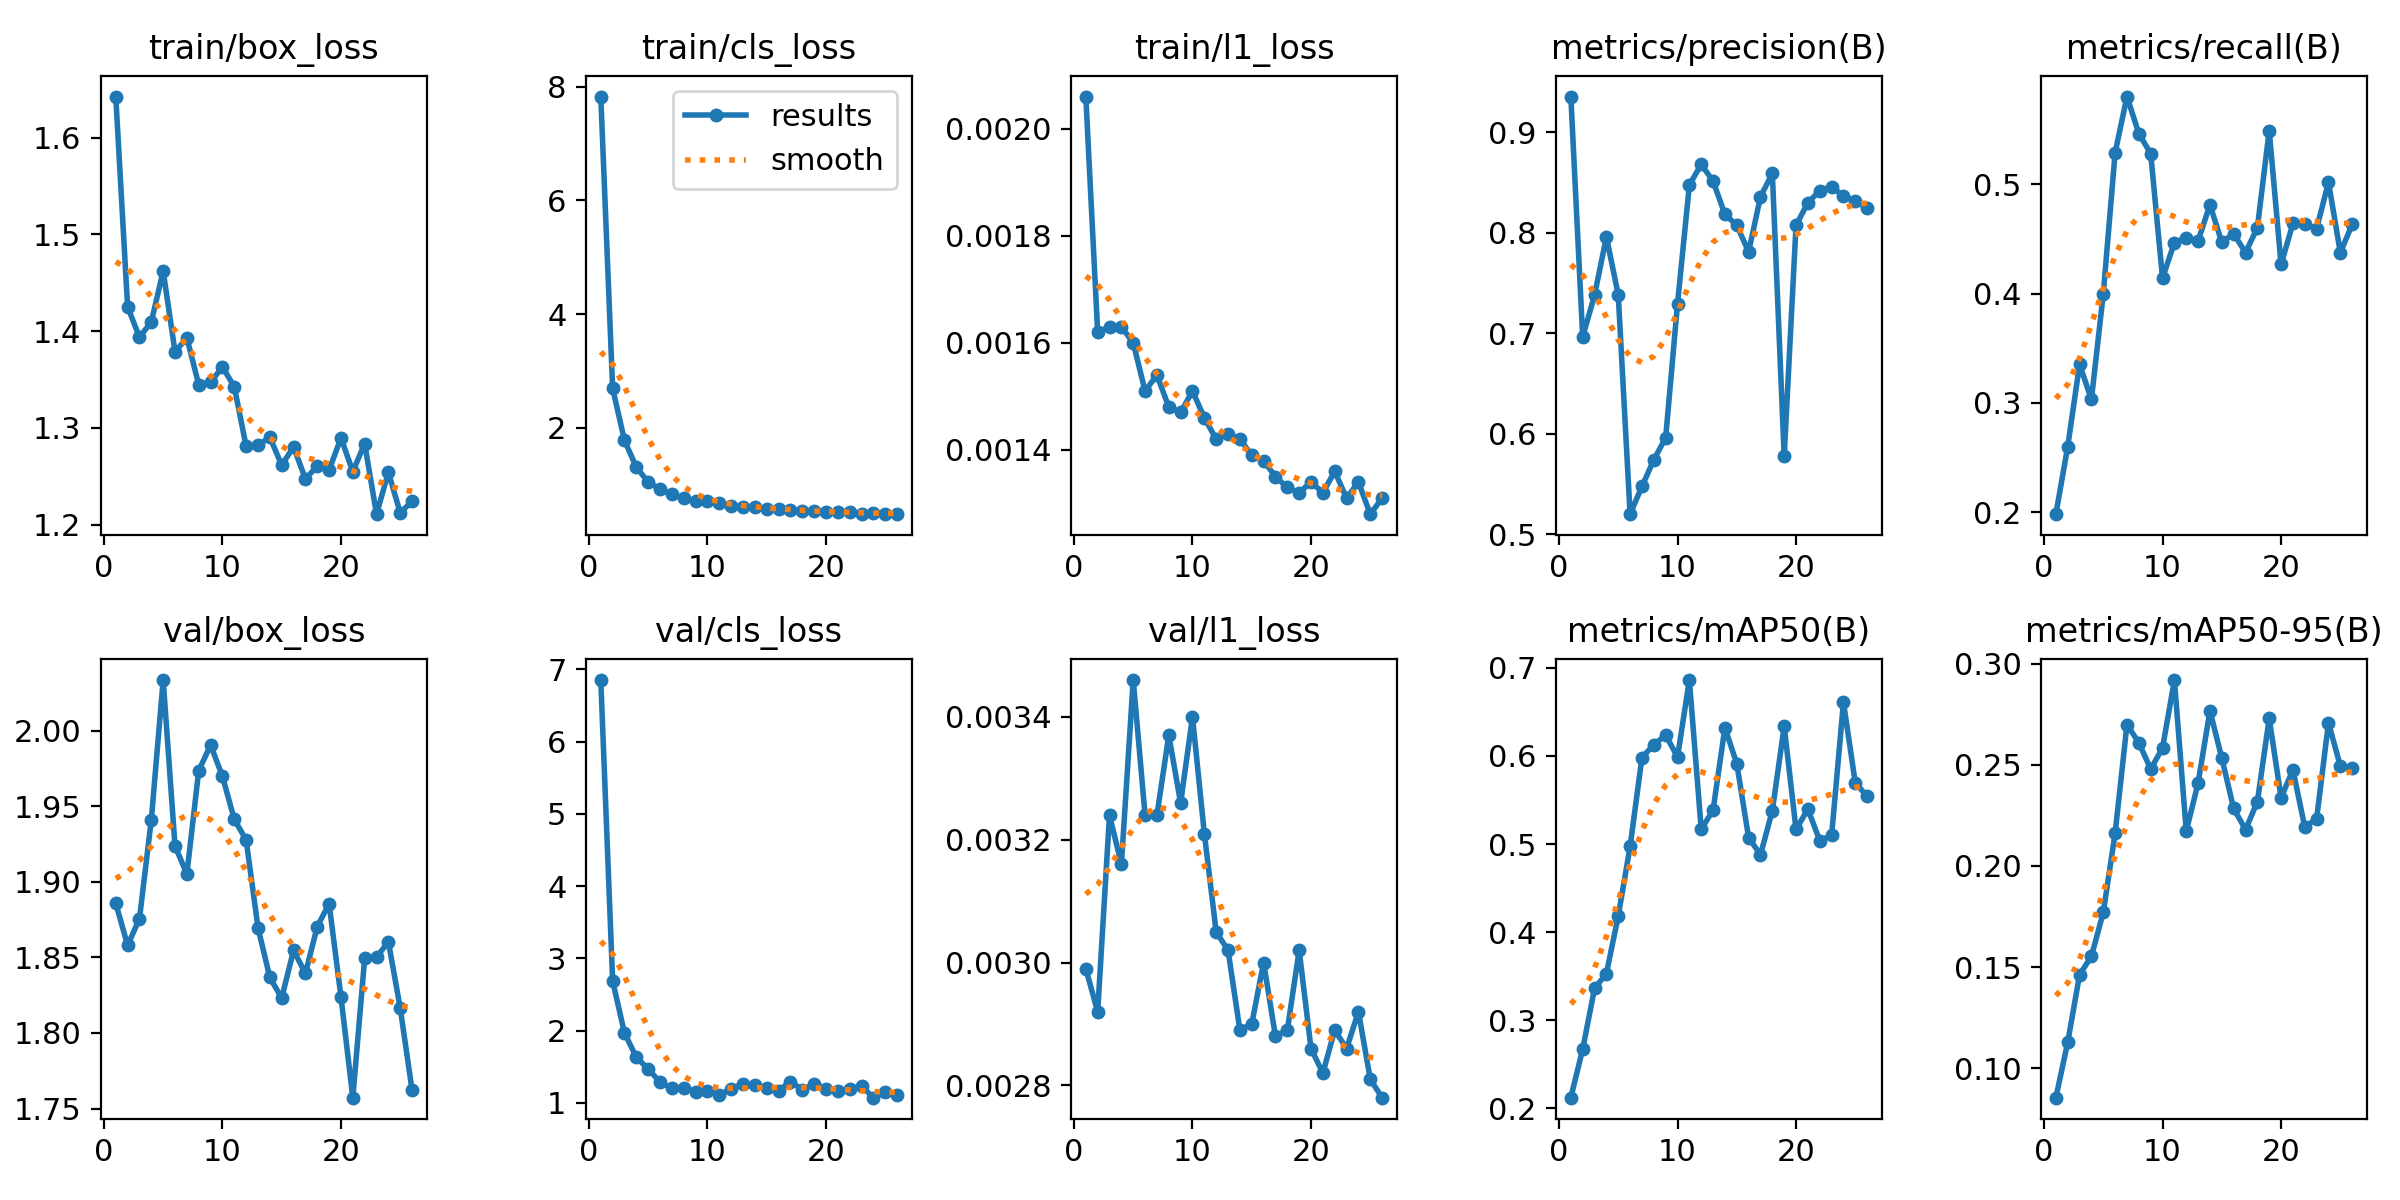

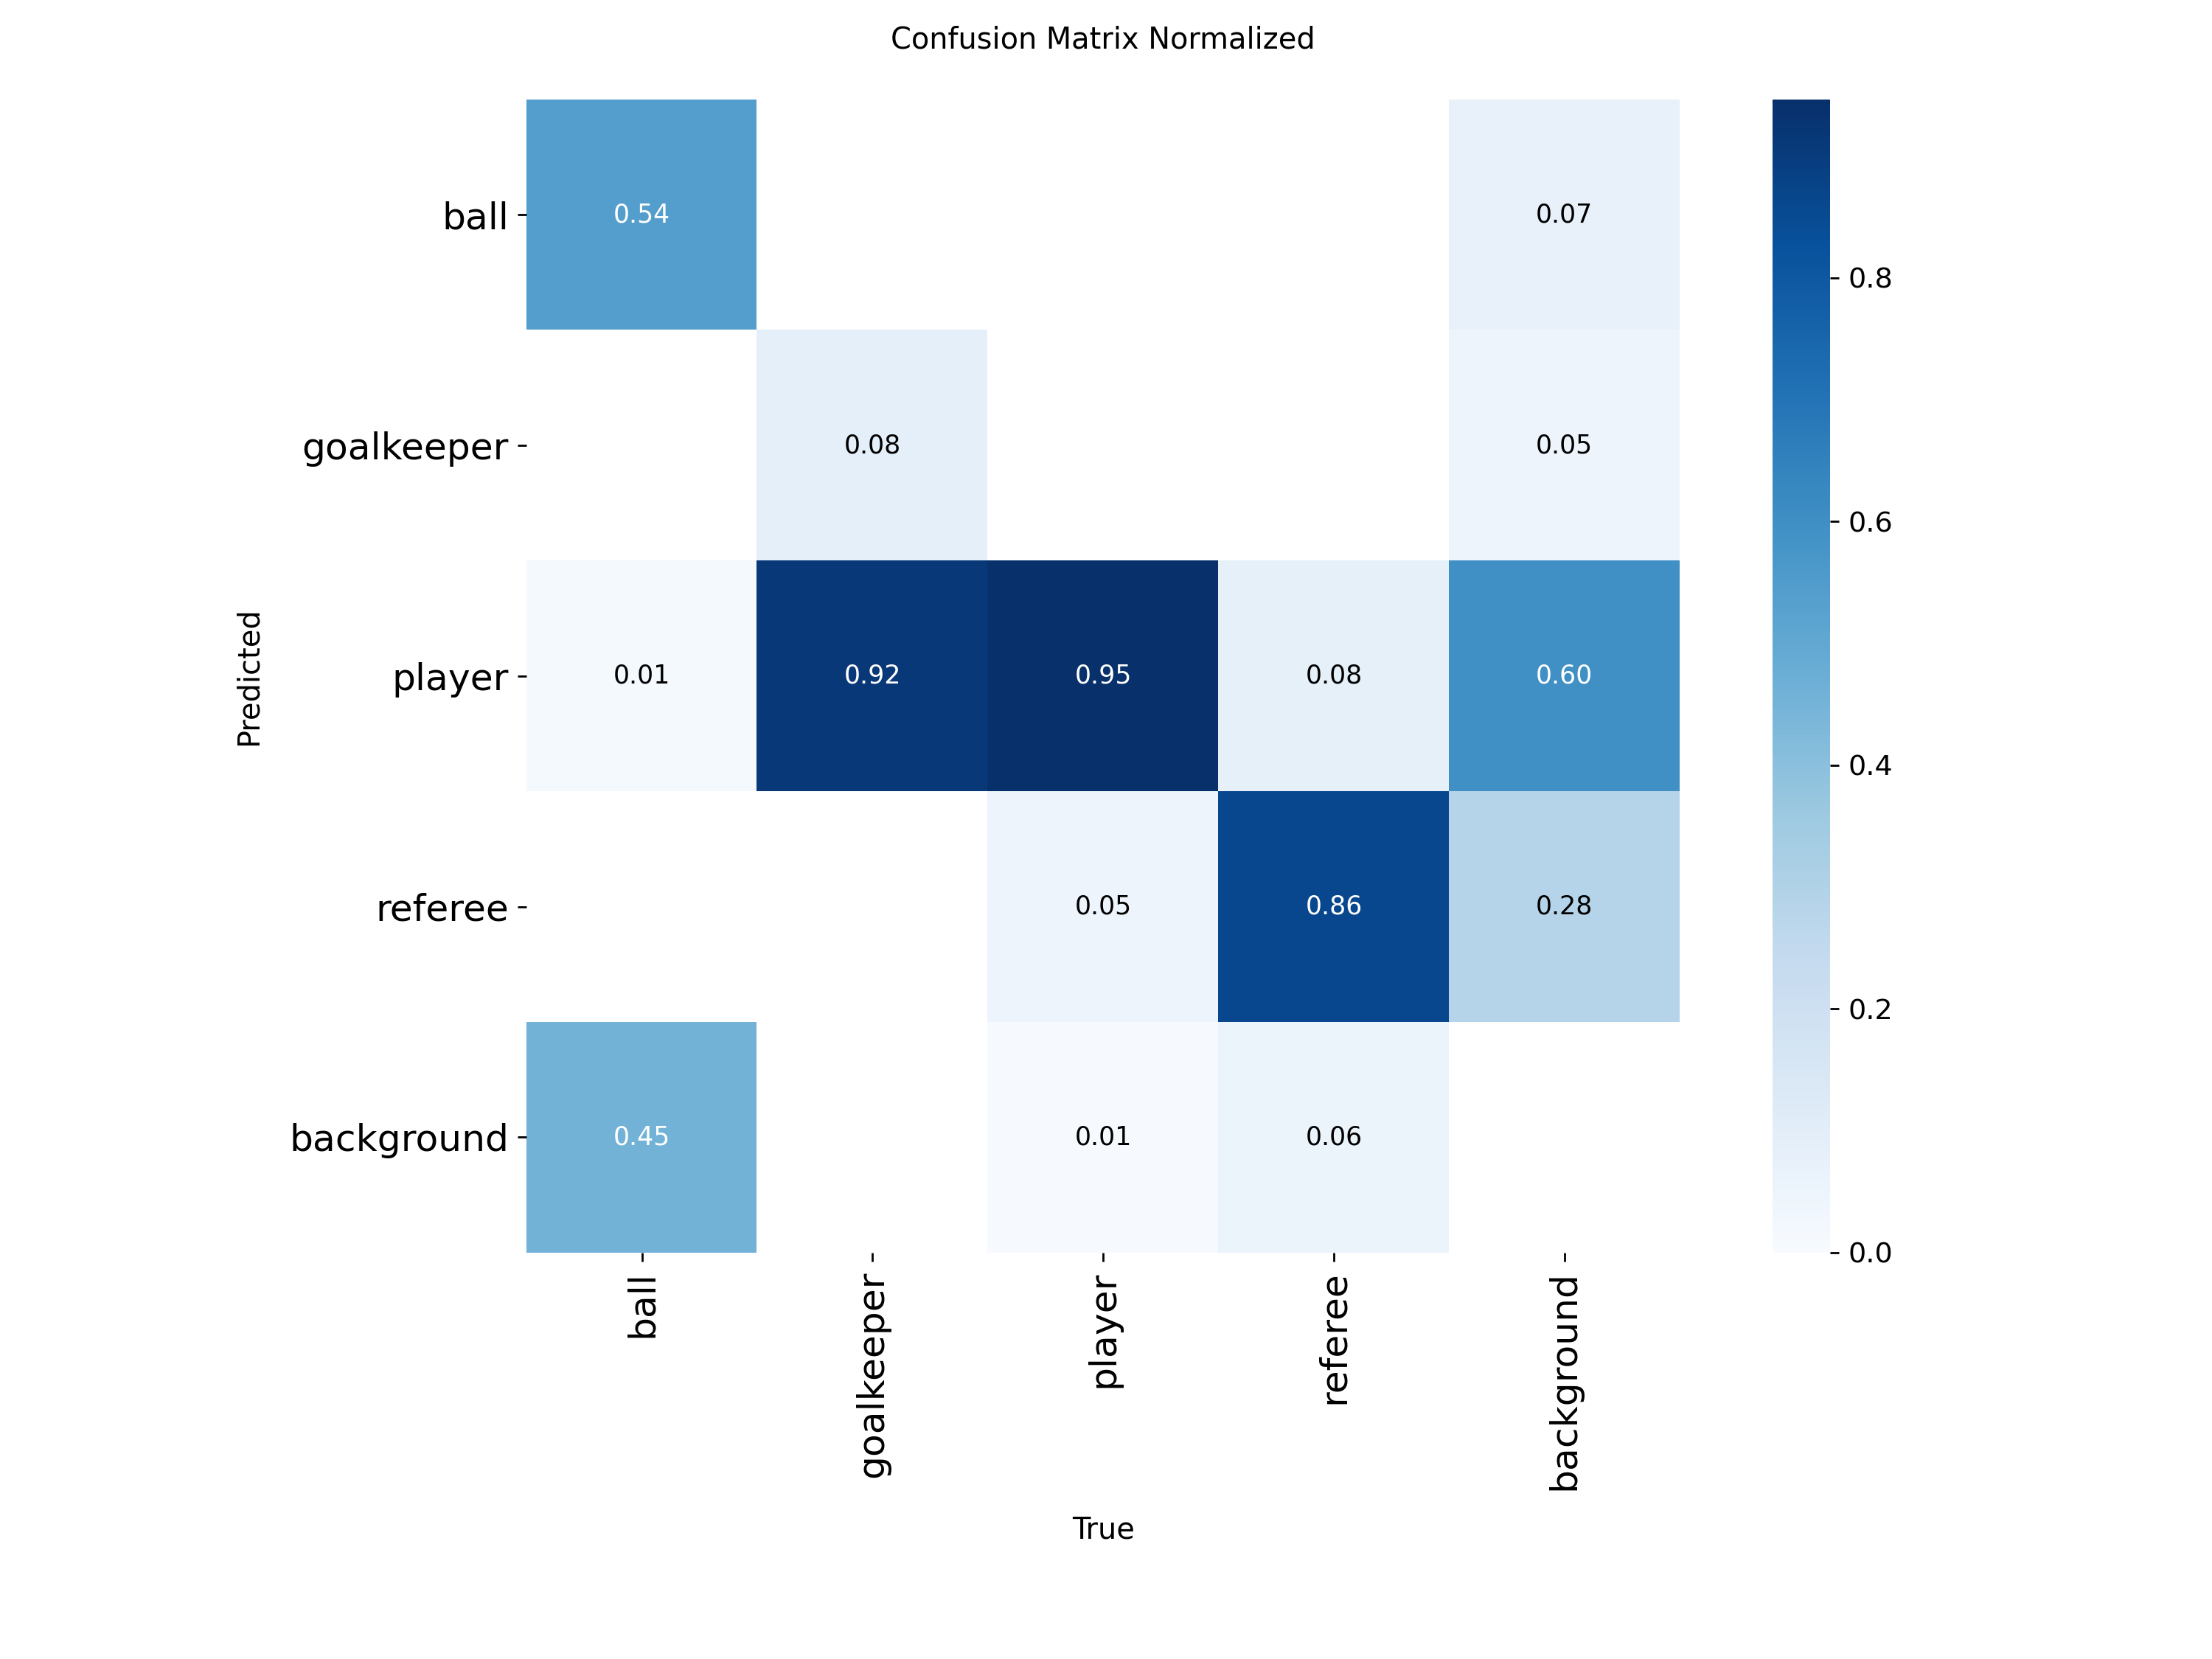

Ultralytics 8.4.189 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1811.2±370.9 MB/s, size: 56.8 KB)
val: Scanning /kaggle/working/football/test/labels... 89 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 89/89 1.1Kit/s 0.1s
val: New cache created: /kaggle/working/football/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 1.5it/s 4.1s0.6ss
                   all         89       2086      0.839      0.693      0.748       0.46
                  ball         75         75      0.769       0.36      0.396      0.161
            goalkeeper         71         73      0.987      0.753      0.862      0.551
                player         89       1722      0.891      0.958      0.972      0.657
               referee         89        216       0.71      0.699 

In [11]:
from IPython.display import Image, display
run = f'{RUNS}/n_960'
display(Image(f'{run}/results.png'))
display(Image(f'{run}/confusion_matrix_normalized.png'))

best = YOLO(f'{run}/weights/best.pt')
m = best.val(data=DATA, split='test')
print('test mAP50:', m.box.map50, ' mAP50-95:', m.box.map)

!cp {run}/weights/best.pt /kaggle/working/n_960_best.pt